# California Housing Price Prediction: OLS vs Ridge vs Lasso

## Step 1: Load the dataset

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('housing.txt')   # update path if needed
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Step 2: Impute null values and compute correlation heatmap

In [2]:
print(df.isnull().sum())
# total_bedrooms has nulls -> median imputation (done inside the pipeline later to avoid leakage)

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


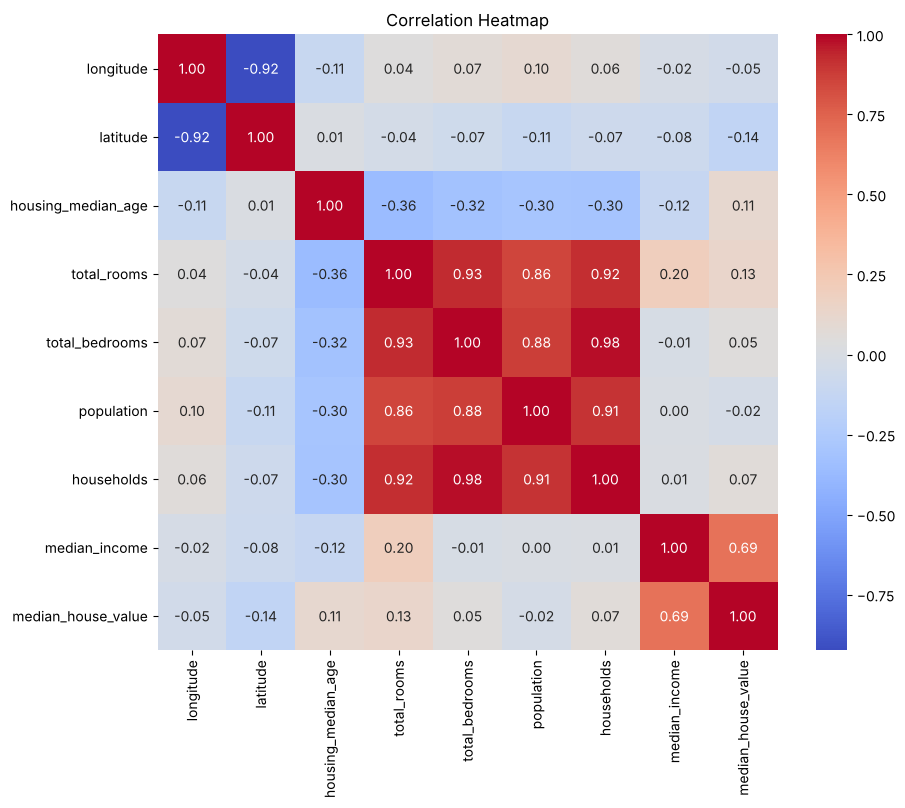

In [3]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop(columns='ocean_proximity').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### Feature engineering (interaction / ratio features)
These also help with multicollinearity: `total_rooms`, `total_bedrooms`, `households`, `population` are highly correlated, so per-household ratios are used.

In [4]:
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']
df['income_x_age'] = df['median_income'] * df['housing_median_age']   # interaction feature
df['income_x_rooms'] = df['median_income'] * df['rooms_per_household']  # interaction feature

# Multicollinearity check with VIF (on imputed numeric data)
from statsmodels.stats.outliers_influence import variance_inflation_factor
num = df.drop(columns=['median_house_value', 'ocean_proximity'])
num = num.fillna(num.median())
vif = pd.DataFrame({'feature': num.columns,
                    'VIF': [variance_inflation_factor(num.values, i) for i in range(num.shape[1])]})
vif.sort_values('VIF', ascending=False)

,feature,VIF
4,total_bedrooms,34.372140
6,households,34.072471
7,median_income,20.038922
12,income_x_rooms,18.351178
3,total_rooms,17.940696
1,latitude,9.584856
0,longitude,9.243571
11,income_x_age,9.225491
5,population,6.708393
2,housing_median_age,5.463654


In [5]:
# Drop raw count columns that are redundant with the ratio features (reduces multicollinearity)
df = df.drop(columns=['total_rooms', 'total_bedrooms'])

## Step 3: Standardize continuous variables and encode categorical attributes

In [6]:
X = df.drop(columns='median_house_value')
y = df['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = ['ocean_proximity']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

## Step 4: Fit OLS, Ridge and Lasso (GridSearchCV over alpha)

In [7]:
ols = Pipeline([('prep', preprocessor), ('model', LinearRegression())]).fit(X_train, y_train)

alphas = np.logspace(-3, 3, 13)

ridge_gs = GridSearchCV(
    Pipeline([('prep', preprocessor), ('model', Ridge())]),
    {'model__alpha': alphas}, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
).fit(X_train, y_train)

lasso_gs = GridSearchCV(
    Pipeline([('prep', preprocessor), ('model', Lasso(max_iter=20000))]),
    {'model__alpha': alphas}, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
).fit(X_train, y_train)

print('Best Ridge alpha:', ridge_gs.best_params_)
print('Best Lasso alpha:', lasso_gs.best_params_)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.859073e+12, tolerance: 1.755e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.871347e+12, tolerance: 1.779e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.913214e+12, tolerance: 1.763e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.839888e+12, tolerance: 1.776e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.821587e+12, tolerance: 1.757e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.859079e+12, tolerance: 1.755e+10
  model = cd_fast.enet_coordinate_descent(


... (16 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.021077e+12, tolerance: 1.763e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.000736e+12, tolerance: 1.776e+10
  model = cd_fast.enet_coordinate_descent(


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.005376e+12, tolerance: 1.757e+10
  model = cd_fast.enet_coordinate_descent(


Best Ridge alpha: {'model__alpha': np.float64(1.0)}
Best Lasso alpha: {'model__alpha': np.float64(3.1622776601683795)}


In [8]:
models = {'OLS': ols, 'Ridge (L2)': ridge_gs.best_estimator_, 'Lasso (L1)': lasso_gs.best_estimator_}
rows, preds = [], {}
for name, m in models.items():
    p = m.predict(X_test); preds[name] = p
    rows.append({'Model': name,
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'MAE': mean_absolute_error(y_test, p),
                 'R2': r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,RMSE,MAE,R2
Model,,,
OLS,68838.5581,49411.2758,0.6384
Ridge (L2),68846.9232,49416.4130,0.6383
Lasso (L1),68843.3624,49413.1928,0.6383


In [9]:
# Coefficient comparison (shows Lasso shrinking/zeroing features)
feat_names = ols.named_steps['prep'].get_feature_names_out()
coefs = pd.DataFrame({n: m.named_steps['model'].coef_ for n, m in models.items()}, index=feat_names)
coefs.round(1)

,OLS,Ridge (L2),Lasso (L1)
num__longitude,-55435.2,-55382.7,-55385.7
num__latitude,-55930.8,-55884.0,-55889.6
num__housing_median_age,6618.4,6600.8,6601.2
num__population,-44530.8,-44503.8,-44499.5
num__households,49203.4,49175.5,49170.6
num__median_income,81594.8,81500.1,81484.3
num__rooms_per_household,14373.5,14339.1,14319.2
num__bedrooms_per_room,17167.3,17163.0,17155.5
num__population_per_household,344.7,342.3,339.5
num__income_x_age,10827.0,10858.1,10846.7


## Step 5: Predicted vs Actual and residual distributions

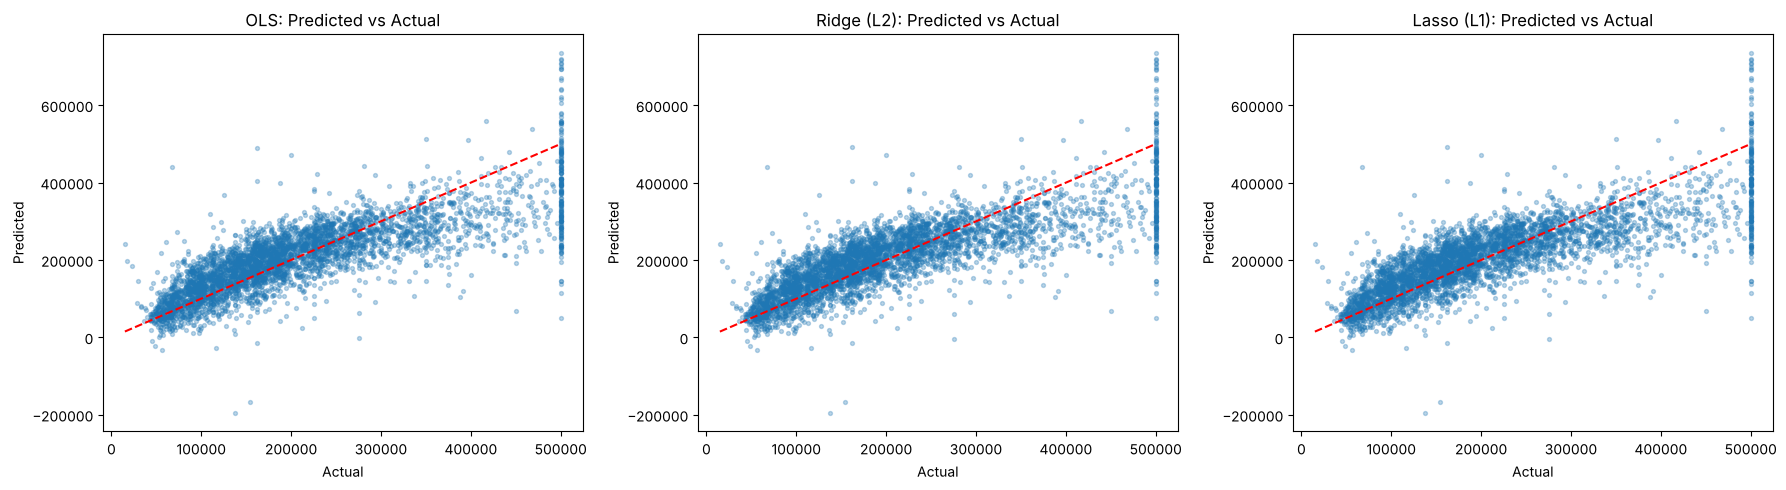

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.3, s=8)
    lims = [y_test.min(), y_test.max()]
    ax.plot(lims, lims, 'r--')
    ax.set_title(f'{name}: Predicted vs Actual')
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
plt.tight_layout(); plt.show()

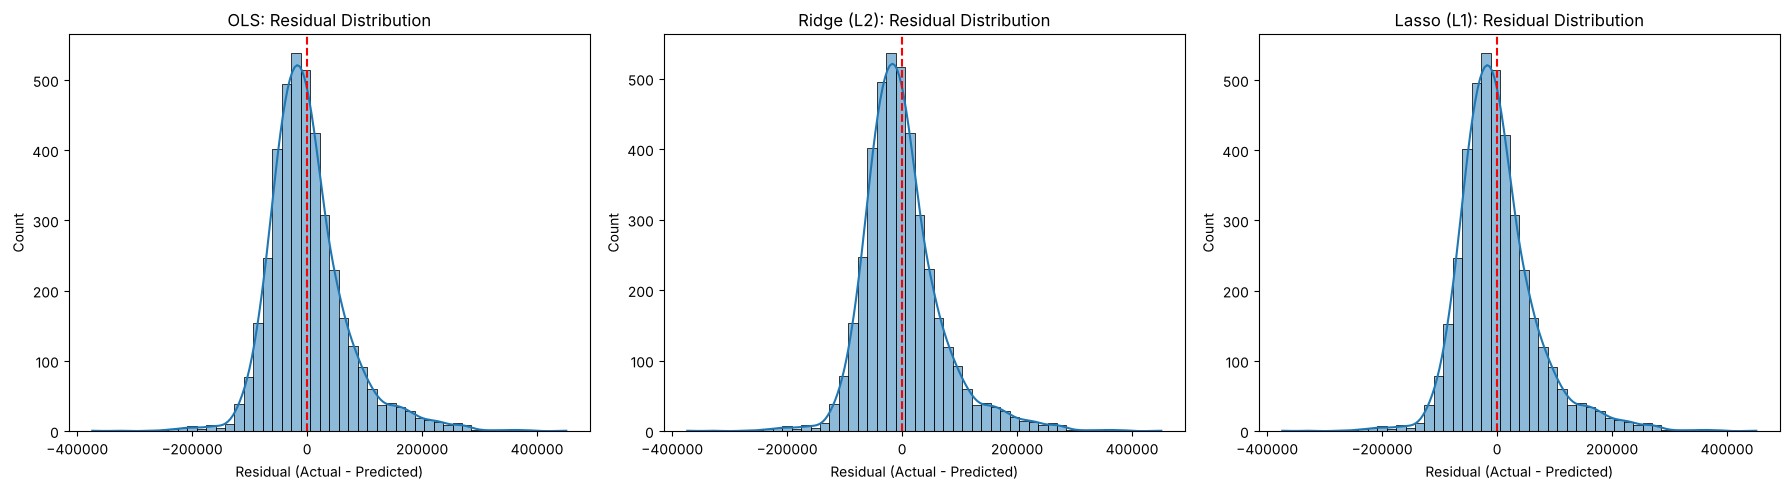

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, p) in zip(axes, preds.items()):
    sns.histplot(y_test - p, kde=True, ax=ax, bins=50)
    ax.axvline(0, color='r', linestyle='--')
    ax.set_title(f'{name}: Residual Distribution')
    ax.set_xlabel('Residual (Actual - Predicted)')
plt.tight_layout(); plt.show()

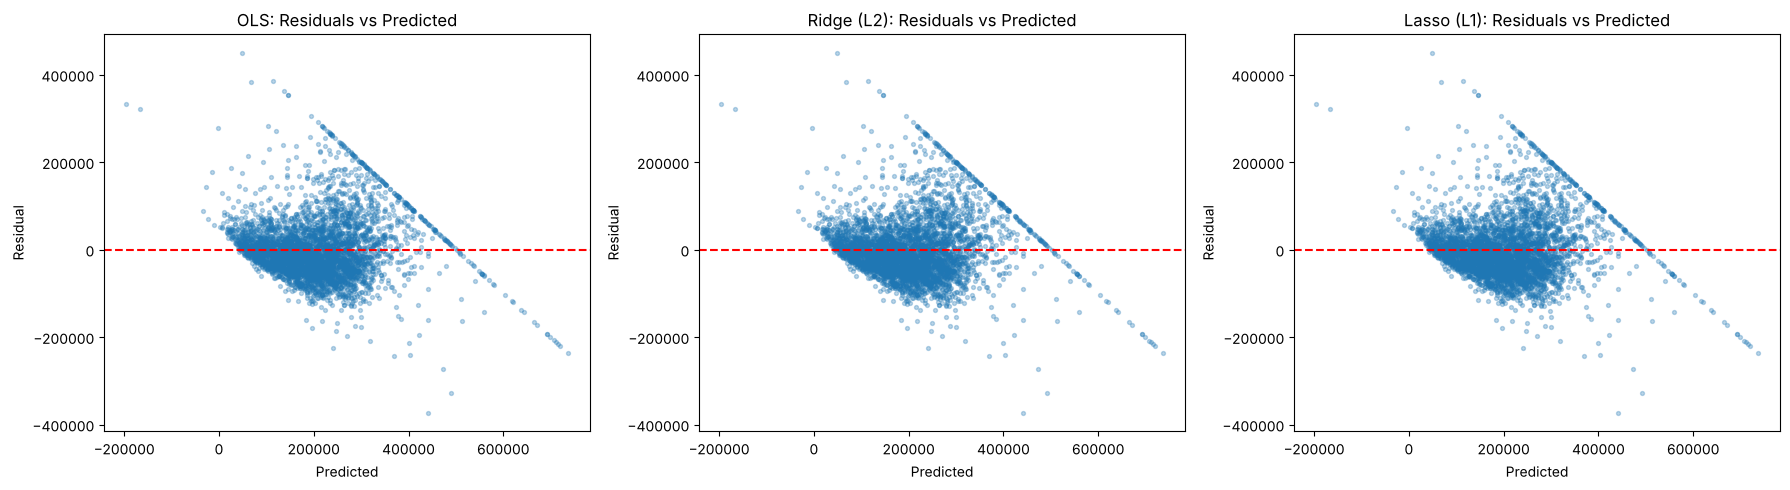

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(p, y_test - p, alpha=0.3, s=8)
    ax.axhline(0, color='r', linestyle='--')
    ax.set_title(f'{name}: Residuals vs Predicted')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Residual')
plt.tight_layout(); plt.show()

## Conclusion
Compare the metrics table above. Ridge and Lasso typically perform close to OLS here because the dataset is large and multicollinearity was already reduced by feature engineering; Lasso additionally performs feature selection.